# Analísis de Clustering - devalign-ml

Este cuaderno permite ejecutar el pipeline de clustering de habilidades técnicas usando **UMAP** y **HDBSCAN**, calcular el **Silhouette Score** y generar la visualización correspondiente.

Puedes ejecutarlo localmente o cargarlo directamente en **Google Colab** desde tu repositorio de GitHub.

## 1. Configuración del Entorno (Solo para Google Colab)

Si estás corriendo este cuaderno en Google Colab, ejecuta la siguiente celda para clonar tu repositorio, instalar dependencias y añadir el directorio al PATH de ejecución de Python.

In [13]:
# Verificar si estamos en Google Colab
try:
    import google.colab
    from google.colab import userdata
    IN_COLAB = True
except:
    IN_COLAB = False

if IN_COLAB:
    import os
    import sys

    # Obtener el token de forma segura
    try:
        github_token = userdata.get('GITHUB_TOKEN')
    except userdata.SecretNotFoundError:
        print("Error: No se encontró GITHUB_TOKEN en los secretos de Colab. Revisa el menú lateral.")
        github_token = None

    if github_token:
        # Inyectar el token en la URL de clonación
        REPO_URL = f"https://{github_token}@github.com/devalign/devalign-ml.git"
        repo_name = "devalign-ml"

        # Clonar el repositorio y moverse a la carpeta
        if not os.path.exists(repo_name):
            !git clone {REPO_URL}
        else:
            print("El repositorio ya estaba clonado. Actualizando...")
            # Si ya existe, actualizamos los cambios
            os.chdir(repo_name)
            !git pull
            os.chdir('..')

        # Entrar a la carpeta
        os.chdir(repo_name)
        print(f"Directorio de trabajo: {os.getcwd()}")

        # Instalar dependencias requeridas
        !pip install -r requirements.txt

        # Agregar la carpeta al path de Python para importar los módulos de src
        sys.path.append(os.getcwd())
else:
    print("Corriendo en entorno local. Asegúrate de tener activado tu entorno virtual.")

Cloning into 'devalign-ml'...
remote: Enumerating objects: 17, done.
remote: Counting objects: 100% (17/17), done.
remote: Compressing objects: 100% (15/15), done.
remote: Total 17 (delta 0), reused 17 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (17/17), 14.81 KiB | 7.40 MiB/s, done.
Directorio de trabajo: /content/devalign-ml/devalign-ml/devalign-ml


## 2. Variables de Entorno y Credenciales

Carga tus variables de entorno para conectarte a la base de datos de Supabase y la API de Groq.

*Tip para Colab:* En lugar de subir un archivo `.env`, puedes ir a la barra lateral izquierda en Google Colab, dar clic en el ícono de llave (**Secrets** o **Claves**) e introducir `SUPABASE_URL`, `SUPABASE_SERVICE_ROLE_KEY` y `GROQ_API_KEY` de forma segura.

In [14]:
import os
import sys
from dotenv import load_dotenv

load_dotenv()

# Intentar cargar desde Secrets de Colab si aplica
try:
    from google.colab import userdata
    os.environ["SUPABASE_URL"] = userdata.get("SUPABASE_URL")
    os.environ["SUPABASE_SERVICE_ROLE_KEY"] = userdata.get("SUPABASE_SERVICE_ROLE_KEY")
    os.environ["GROQ_API_KEY"] = userdata.get("GROQ_API_KEY")
    print("Variables de entorno cargadas con éxito desde Colab Secrets.")
except:
    print("Buscando archivo .env local para credenciales...")

Variables de entorno cargadas con éxito desde Colab Secrets.


## 3. Carga y Procesamiento de Datos

Cargaremos los datos de habilidades y ofertas. La primera vez se descargarán de Supabase y se guardarán en la caché local (`data/raw_*.json`) para que las siguientes ejecuciones sean instantáneas sin saturar la base de datos.

In [15]:
from google.colab import userdata

try:
    # Extraemos usando los nombres EXACTOS de tu panel derecho
    url_secreta = userdata.get('SUPABASE_URL')
    llave_secreta = userdata.get('SUPABASE_SERVICE_ROLE_KEY')

    # Inyectamos a la fuerza en el repositorio
    import src.config
    src.config.SUPABASE_URL = url_secreta
    src.config.SUPABASE_KEY = llave_secreta

    print("✅ Llaves inyectadas a la fuerza en src.config correctamente.")
except userdata.SecretNotFoundError as e:
    print(f"❌ Error crítico: {e}")

# Ahora sí, importar las funciones y ejecutarlas
from src.data_loader import load_raw_data, process_job_offer_vectors
import numpy as np

# Cargar datos (intentando usar caché primero)
skills_data, offers_data = load_raw_data(use_cache=True)
valid_offers, alias_to_canonical = process_job_offer_vectors(skills_data, offers_data)

vectors = np.array([o["vector"] for o in valid_offers])
print(f"\n🚀 Embeddings de ofertas listos para clustering: {vectors.shape}")

✅ Llaves inyectadas a la fuerza en src.config correctamente.

🚀 Embeddings de ofertas listos para clustering: (1131, 1024)


## 4. Ejecución del Clustering (UMAP + HDBSCAN)

Reduciremos las dimensiones e iniciaremos el algoritmo de clustering HDBSCAN. Veremos el Silhouette Score final.

In [16]:
from src.clustering import ClusteringPipeline

pipeline = ClusteringPipeline()
results = pipeline.run(vectors)

print("\n" + "=" * 50)
print(f"METRICA - Silhouette Score (excl. ruido): {results['silhouette_score']:.4f}")
print("=" * 50)

/usr/local/lib/python3.12/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(



METRICA - Silhouette Score (excl. ruido): 0.5609


## 5. Visualización Gráfica para el PPT

La gráfica de dispersión a continuación muestra la distribución bidimensional obtenida mediante UMAP y cómo HDBSCAN agrupa las ofertas de trabajo. Puedes tomarle captura de pantalla a este gráfico junto al Silhouette Score para tu presentación.

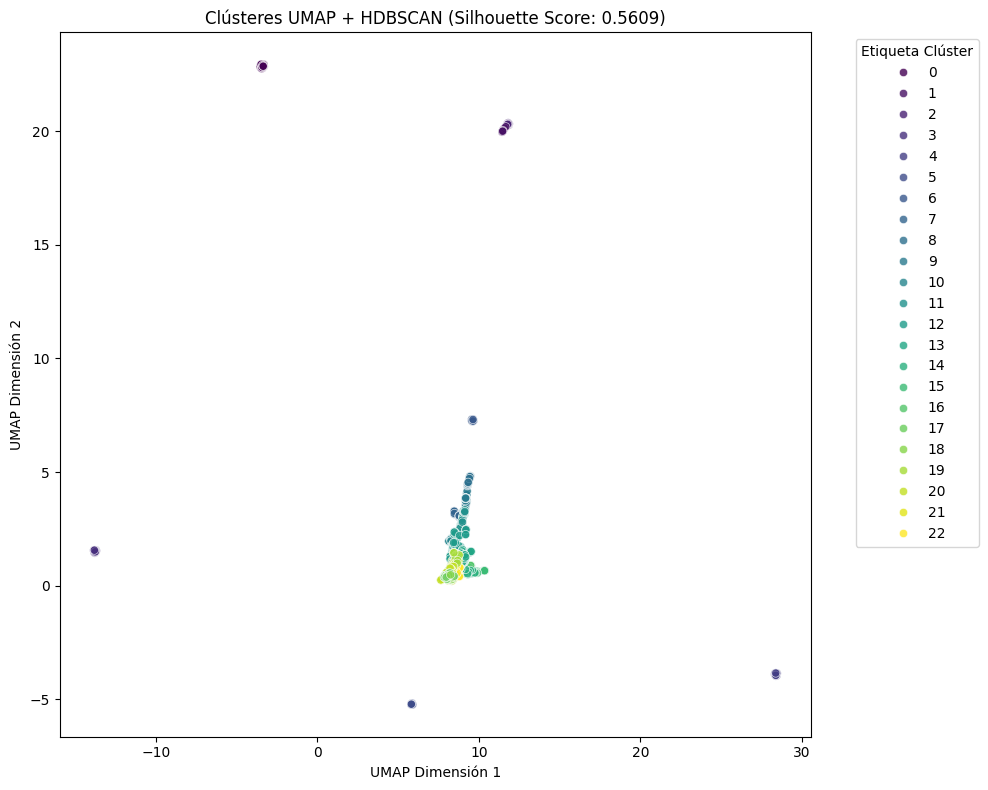

In [17]:
%matplotlib inline
import matplotlib.pyplot as plt
import seaborn as sns

X_reduced = results["X_reduced"]
labels = results["final_labels"]

plt.figure(figsize=(10, 8))
sns.scatterplot(
    x=X_reduced[:, 0],
    y=X_reduced[:, 1],
    hue=labels,
    palette='viridis',
    legend='full',
    alpha=0.8,
    edgecolor='w',
    linewidth=0.5
)
plt.title(f"Clústeres UMAP + HDBSCAN (Silhouette Score: {results['silhouette_score']:.4f})")
plt.xlabel("UMAP Dimensión 1")
plt.ylabel("UMAP Dimensión 2")
plt.legend(title="Etiqueta Clúster", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()